In [1]:
import os
import warnings
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import yaml

from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.datasets import make_classification
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
import shap
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import compute_sample_weight, shuffle
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
warnings.filterwarnings("ignore")

/opt/anaconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_data(path):
    files = os.listdir(path)
    df = pd.read_csv(os.path.join(path, files[0]))
    return df
df = load_data("/Users/enkhjin/.cache/kagglehub/datasets/saurabhbadole/bank-customer-churn-prediction-dataset/versions/2")
print(df.head())  

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

In [3]:
def load_config(path=None):
    if path is not None:
        config_path = Path(path)
        if not config_path.is_file():
            raise FileNotFoundError(f"Configuration file not found: {config_path}")
    else:
        config_candidates = (
            Path("configs.yaml"),
            Path("../configs.yaml"),
            Path("config/configs.yaml"),
            Path("../config/configs.yaml"),
        )
        config_path = next((candidate for candidate in config_candidates if candidate.is_file()), None)
        if config_path is None:
            searched = ", ".join(str(candidate) for candidate in config_candidates)
            raise FileNotFoundError(f"Could not find configs.yaml; searched: {searched}")

    with config_path.open("r", encoding="utf-8") as config_file:
        return yaml.safe_load(config_file)

config = load_config()
print(config)

{'rf_model': {'type': 'RandomForestClassifier', 'random_state': 42, 'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 15, 'bootstrap': True, 'class_weight': 'balanced_subsample'}, 'lr_model': {'type': 'LogisticRegression', 'random_state': 42, 'max_iter': 150, 'C': 0.01}, 'gb_model': {'type': 'GradientBoostingClassifier', 'loss': 'log_loss', 'learning_rate': 0.1, 'subsample': 1.0, 'max_features': 'None', 'n_estimators': 50, 'max_depth': 5, 'min_samples_split': 10, 'min_samples_leaf': 1, 'random_state': 42}}


In [4]:
def check_missing_duplicated_values(df):
    if df.empty:
        print("The DataFrame is empty.")
        return None, None
    missing_values = df.isnull().any()
    duplicated_rows = df.duplicated().any()
    check = missing_values.sum() or duplicated_rows.sum()
    if missing_values.sum() > 0:
        print("There are missing values in the DataFrame.")
    if duplicated_rows.sum() > 0:
        print("There are duplicated rows in the DataFrame.")
    return check
if __name__ == "__main__":
    print(check_missing_duplicated_values(df))
    

0


In [5]:
def number_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return 0
    numeric_columns = df.select_dtypes(include=['number']).shape[1]
    return numeric_columns
if __name__ == "__main__":
    print("Number of numeric columns:", number_columns(df))

Number of numeric columns: 11


In [6]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [7]:
('line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin')

('line',
 'bar',
 'barh',
 'kde',
 'density',
 'area',
 'hist',
 'box',
 'pie',
 'scatter',
 'hexbin')

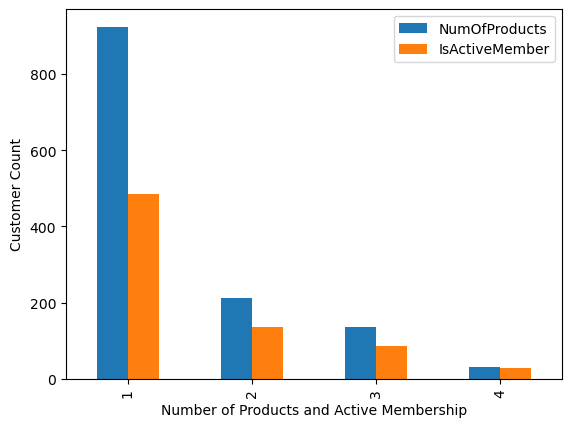

In [8]:
exited = df[df['Exited'] == 1]
value_counts = pd.crosstab(
    exited['NumOfProducts'], exited['IsActiveMember']
)

value_counts.plot(kind='bar')
plt.xlabel('Number of Products and Active Membership')
plt.ylabel('Customer Count')
plt.legend(['NumOfProducts', 'IsActiveMember'])
plt.show()

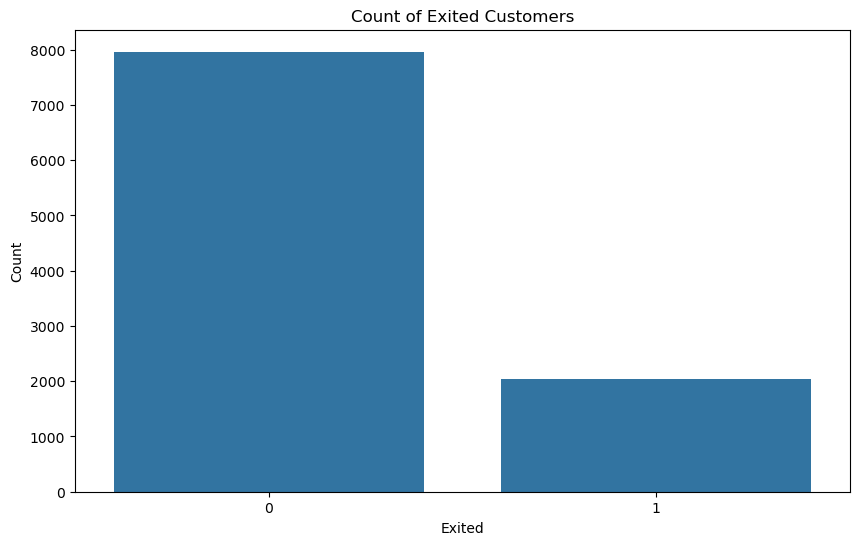

None


In [9]:
def plot(df):
    plt.figure(figsize=(10, 6))
    sns.countplot(x='Exited', data=df)
    plt.title('Count of Exited Customers')
    plt.xlabel('Exited')
    plt.ylabel('Count')
    plt.show()
if __name__ == "__main__":
    print(plot(df))


 We plotted the exited costumers to check the class imbalance, and adjust later on our upsampling strategy. 

In [10]:

print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [11]:
def drop_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return df
    return df.drop(columns=['Surname', 'RowNumber', 'CustomerId'])

df_drop = drop_columns(df)
print(df_drop.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [12]:
def encoding_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return df
    categorical_columns = df.select_dtypes(include=['object']).columns
    print("Categorical columns to encode:", categorical_columns)
    df_encoded = pd.get_dummies(df, drop_first=True,
                                columns = categorical_columns,
                                dtype=int)
    return df_encoded
df_encoded = encoding_columns(df_drop)
print(df_encoded.head())
df_exited = df_encoded[df_encoded['Exited'] == 1]
df_exited.value_counts()

Categorical columns to encode: Index(['Geography', 'Gender'], dtype='object')
   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0               1        101348.88       1                  0   
1               1        112542.58       0                  0   
2               0        113931.57       1                  0   
3               0         93826.63       0                  0   
4               1         79084.10       0                  0   

   Geography_Spain  Gender_Male  
0                0            0  
1                1            0  
2                0  

CreditScore  Age  Tenure  Balance    NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  Geography_Germany  Geography_Spain  Gender_Male
350          39   0       109733.20  2              0          0               123602.11        1       1                  0                1              1
             40   0       111098.85  1              1          1               172321.21        1       0                  0                0              1
             51   10      0.00       1              1          1               125823.79        1       0                  0                1              1
             54   1       152677.48  1              1          1               191973.49        1       0                  1                1              1
             60   3       0.00       1              0          0               113796.15        1       0                  0                0              1
                                                               

Age                  0.285323
Geography_Germany    0.173488
Balance              0.118533
EstimatedSalary      0.012097
HasCrCard           -0.007138
Tenure              -0.014001
CreditScore         -0.027094
NumOfProducts       -0.047820
Geography_Spain     -0.052667
Gender_Male         -0.106512
IsActiveMember      -0.156128
Name: Exited, dtype: float64


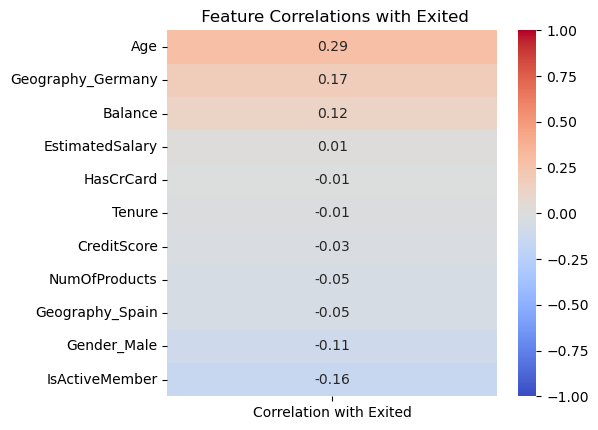

In [13]:
def corr_target(df):
    if df.empty:
        print("The DataFrame is empty.")
        return None
    correlation_matrixxx = df.corr()['Exited']
    correlation_matrix = correlation_matrixxx.drop("Exited").sort_values(ascending=False)
    return correlation_matrix
corr = corr_target(df_encoded)
print(corr)
# corr.plot(kind='bar', x=corr.index, 
#         y=corr.values,
#         title='Correlation with Target Variable (Exited)',
#         xlabel='Features', ylabel='Correlation Coefficient')
# plt.show()
plt.figure(figsize=(6, max(4, len(corr) * 0.4)))
sns.heatmap(
    corr.to_frame(name="Correlation with Exited"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title(" Feature Correlations with Exited")
plt.tight_layout()
plt.show()

In [14]:
df_encoded.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [ ]:
def hypothesis_test(df):
    if df.empty:
        print("The DataFrame is empty.")
        return None
    h0 = df.loc[df['Exited'] == 1, 'CreditScore']
    h1 = df.loc[df['Exited'] == 0, 'CreditScore']
    alpha = 0.05
    results = stats.ttest_ind(h1, h0, equal_var=False)
    decision = "Reject h0" if results.pvalue < alpha else "Fail to reject h0"
    return {
        "mean_left": h0.mean(),
        "mean_stayed": h1.mean(),
        "t_statistic": results.statistic,       
        "p_value": results.pvalue,
        "alpha": alpha,
        "decision": decision,
    }


results = hypothesis_test(df)
if results:
    for k, v in results.items():
        print(f"{k}: {v}")
print("Decision:", results["decision"])

mean_left: 645.3514972999509
mean_stayed: 651.8531960316463
t_statistic: 2.6346605436575796
p_value: 0.008464728991832862
alpha: 0.05
decision: Reject h0
Decision: Reject h0


In [24]:
def splitting_data(df):
    if df.empty:
        print("Dataframe is empty.")
        return None
    config = load_config()
    target = df['Exited']
    features = df.drop(columns=['Exited'], axis=1)
    x_temp,x_test, y_temp,y_test = train_test_split(features, target,
                                                    test_size=0.25, 
                                                    random_state=42,
                                                    stratify=target)
    x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp,
                                                      test_size=0.25, 
                                                      random_state=42,
                                                      stratify=y_temp)
    return x_train, x_val, x_test, y_train, y_val, y_test  
x_train, x_val, x_test, y_train, y_val, y_test = splitting_data(df_encoded)
print(f"Training set: {x_train.shape[0]} samples")
print(f"Validation set: {x_val.shape[0]} samples")


Training set: 5625 samples
Validation set: 1875 samples


In [25]:
print("The training columns are:", x_train.columns)
print("The minimum values in each column are:", [f"{value:.0f}" for value in x_train.min().values])
print("The maximum values in each column are:", [f"{value:.0f}" for value in x_train.max().values])
# print(x_train.head())

The training columns are: Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Geography_Germany',
       'Geography_Spain', 'Gender_Male'],
      dtype='object')
The minimum values in each column are: ['350', '18', '0', '0', '1', '0', '0', '12', '0', '0', '0']
The maximum values in each column are: ['850', '92', '10', '222268', '4', '1', '1', '199992', '1', '1', '1']


In [26]:
def scale_data():
    scaler = StandardScaler()
    scaler.fit(x_train)
    x_valid_scaled = scaler.transform(x_val)
    x_train_scaled = scaler.transform(x_train)  # Apply to training data
    x_test_scaled = scaler.transform(x_test)    # Apply same scaling to test data
    return x_train_scaled, x_valid_scaled, x_test_scaled

x_train, x_val, x_test = scale_data()
print("The training columns are:", x_train.min().round(0))

The training columns are: -3.0


In [27]:
def tuning_hyperparameters_rf(x_train, y_train, x_val, y_val):
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [5, 10, None],
        'class_weight': ['balanced', 'balanced_subsample']
    }
    pipeline = RandomForestClassifier(random_state=42)
    search = GridSearchCV(pipeline, 
                                param_grid=param_grid,
                                scoring='f1', cv=3,
                                n_jobs=-1, refit=True)
    search.fit(x_train, y_train)
    
    prediction = search.predict(x_val)
    precision = precision_score(y_val, prediction)
    recall = recall_score(y_val, prediction)
    return search.best_estimator_, search.best_params_, search.best_score_, precision, recall
                        
best_model_fr, best_params_rf, best_f1_rf, precision_rf, recall_rf = tuning_hyperparameters_rf(x_train, y_train, x_val, y_val)
print("=== Best Results ===")
print(best_model_fr)
print(f"Best f1 score:", best_f1_rf)
print(precision_rf, recall_rf)

=== Best Results ===
RandomForestClassifier(class_weight='balanced_subsample', max_depth=10,
                       n_estimators=200, random_state=42)
Best f1 score: 0.5931773179836822
0.6449086161879896 0.6465968586387435


In [28]:
def tuning_hyperparameters(x_train, y_train, x_val, y_val):
    sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
        )
    

    param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

    model = GradientBoostingClassifier(loss='log_loss', random_state=42)

    search = GridSearchCV(model,
        param_grid=param_grid,
        scoring='f1',
        cv=3,                  # 3-fold cross-validation
        n_jobs=-1,              # Use available CPU cores
        verbose=1
    )
    search.fit(x_train, y_train,  sample_weight=sample_weights)

    best_model = search.best_estimator_

    # Evaluate the best model on the validation set
    prediction = best_model.predict(x_val)

    best_f1 = f1_score(y_val, prediction, zero_division=0)
    precision = precision_score(y_val, prediction, zero_division=0)
    recall = recall_score(y_val, prediction, zero_division=0)

    best_params = search.best_params_

    return best_model, best_params, search.best_score_, precision, recall

best_model_gb, best_params_gb, best_f1_gb, precision_gb, recall_gb = tuning_hyperparameters(x_train, y_train, x_val, y_val)
print("=== Best Results ===")
print("Best model:", best_model_gb)
print("Best parameters:", best_params_gb)
print("Validation F1:", best_f1_gb)
print("Validation precision:", precision_gb)
print("Validation recall:", recall_gb)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
=== Best Results ===
Best model: GradientBoostingClassifier(n_estimators=50, random_state=42)
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
Validation F1: 0.7670967869202094
Validation precision: 0.4957983193277311
Validation recall: 0.7722513089005235


In [29]:
def tuning_hyperparameter_lr(x_train, y_train, x_val, y_val):
    param_grid = {
        'C': [0.01, 0.1, 1.0, 10.0],
        'penalty': ['l1', 'l2'], 
        'max_iter': [150, 200, 300]
}

    model = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')

    random_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring='f1',
        cv=3,                  # 3-fold cross-validation
        n_jobs=-1,              # Use available CPU cores
        verbose=1
    )
    random_search.fit(x_train, y_train)

    best_model = random_search.best_estimator_

    # Evaluate the best model on the validation set
    prediction = best_model.predict(x_val)

    best_f1 = f1_score(y_val, prediction, zero_division=0)
    precision = precision_score(y_val, prediction, zero_division=0)
    recall = recall_score(y_val, prediction, zero_division=0)

    best_params = random_search.best_params_

    return best_model, best_params, random_search.best_score_, precision, recall


best_model_lr, best_params_lr, best_f1_lr, precision_lr, recall_lr = tuning_hyperparameter_lr(x_train, y_train, x_val, y_val)
print("=== Best Results ===")
print("Best model:", best_model_lr)
print("Best parameters:", best_params_lr)
print("Validation F1:", best_f1_lr)
print("Validation precision:", precision_lr)
print("Validation recall:", recall_lr)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
=== Best Results ===
Best model: LogisticRegression(C=0.1, class_weight='balanced', max_iter=150, penalty='l1',
                   random_state=42, solver='liblinear')
Best parameters: {'C': 0.1, 'max_iter': 150, 'penalty': 'l1'}
Validation F1: 0.4866327419420647
Validation precision: 0.3564625850340136
Validation recall: 0.6858638743455497


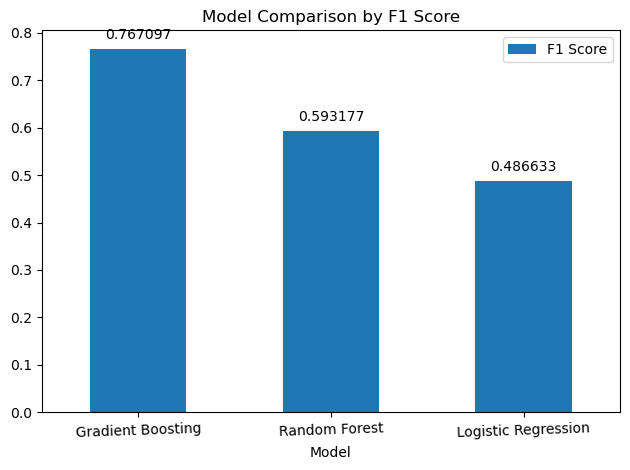

In [30]:
compare_models = pd.DataFrame({'Model':['Random Forest', 'Logistic Regression', 'Gradient Boosting'],
                               'F1 Score':[best_f1_rf, best_f1_lr, best_f1_gb]})
compare_models.sort_values(by='F1 Score', ascending=False, inplace=True)
comp_models = compare_models.plot(kind='bar', x='Model', y='F1 Score', title='Model Comparison by F1 Score')    
for bars in comp_models.containers:
    comp_models.bar_label(bars, fmt="%.6f", padding=5)
plt.xticks(rotation=2)
plt.tight_layout()
plt.show()

In [31]:
def upsample(features, target, repeat=4, random_state=42):
    """Repeat the minority class (label 1) `repeat` times in total. Use on TRAINING data only."""
    X = pd.DataFrame(features).reset_index(drop=True)
    y = pd.Series(np.asarray(target).ravel(), name="Exited")   # force 1-D, same positional index as X

    # Guards: fail loudly instead of silently producing garbage
    if len(X) != len(y):
        raise ValueError(f"Length mismatch: X={len(X)}, y={len(y)}")
    if X.isna().any().any():
        raise ValueError("Input features already contain NaN")
    if not set(y.unique()) <= {0, 1}:
        raise ValueError(f"Target must be binary 0/1, got {y.unique()}")

    minority = y == 1
    X_up = pd.concat([X[~minority]] + [X[minority]] * repeat, ignore_index=True)
    y_up = pd.concat([y[~minority]] + [y[minority]] * repeat, ignore_index=True)
    X_up, y_up = shuffle(X_up, y_up, random_state=random_state)

    # Post-conditions
    assert not X_up.isna().any().any(), "NaN appeared during upsampling"
    assert len(X_up) == len(y_up)
    return X_up, y_up
x_train_up, y_train_up = upsample(x_train, y_train)
print(type(x_train_up))
print(x_train_up.shape)
print(type(y_train_up))
print(y_train_up.shape)

<class 'pandas.core.frame.DataFrame'>
(9063, 11)
<class 'pandas.core.series.Series'>
(9063,)


In [34]:
def model_training_gb(x_train, y_train, x_val, y_val):
    upsample_model = GradientBoostingClassifier(random_state=config['gb_model']['random_state'],
                                                     n_estimators=config['gb_model']['n_estimators'],
                                                     max_depth=config['gb_model']['max_depth'],
                                                     learning_rate=config['gb_model']['learning_rate'],
                                                     subsample=config['gb_model']['subsample'])
                                                    # class_weight =config['rf_model']['class_weight']
                                                    
    upsample_model.fit(x_train, y_train)
    prediction = upsample_model.predict(x_val)
    precision = precision_score(y_val, prediction)
    f1 = f1_score(y_val, prediction)
    return prediction, precision, f1, upsample_model
prediction_upsample, precision_upsample, f1_upsample, upsample_model = model_training_gb(x_train_up, y_train_up, x_val, y_val)
print("Best model with upsampling:", upsample_model)
print("Best f1 with upsampling:", f1_upsample)

Best model with upsampling: GradientBoostingClassifier(max_depth=5, n_estimators=50, random_state=42)
Best f1 with upsampling: 0.6188436830835118


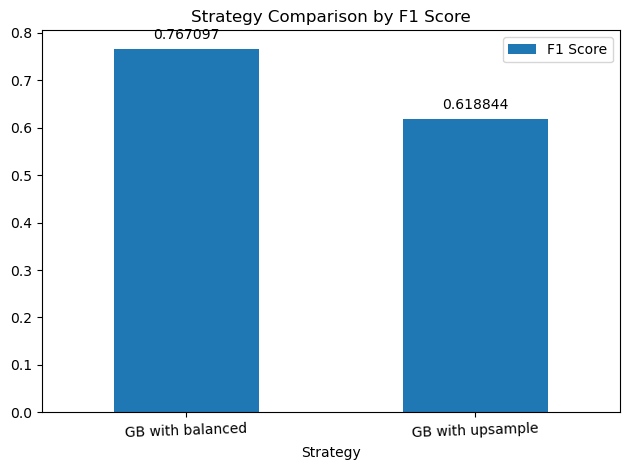

In [35]:
compare_strategy = pd.DataFrame({'Strategy':['GB with balanced', 'GB with upsample'],
                               'F1 Score':[best_f1_gb,f1_upsample]})
compare_strategy.sort_values(by='F1 Score', ascending=False, inplace=True)
comp_strat = compare_strategy.plot(kind='bar', x='Strategy', y='F1 Score', title='Strategy Comparison by F1 Score')    
for bars in comp_strat.containers:
    comp_strat.bar_label(bars, fmt="%.6f", padding=5)
plt.xticks(rotation=2)
plt.tight_layout()
plt.show()

The plot indicated the Gradient Boosting Classifier model with balanced strategy shows the best f1 result. (0.76)

In [36]:
prediction_test, precision_test, f1_test, model_test= model_training_gb(x_train, y_train, x_test, y_test )
print("===================")
print( "The best model:", model_test)
print("The best f1 score on the best model:", f1_test)

The best model: GradientBoostingClassifier(max_depth=5, n_estimators=50, random_state=42)
The best f1 score on the best model: 0.6060606060606061


Conclusion
The dataset contains 10,000 rows and 14 columns. The objective was to predict whether a bank customer would remain with the bank or leave, using the Exited column as the target variable.

The RowNumber, CustomerId, and Surname columns were removed because they do not provide useful predictive information. Logistic Regression, Gradient Boosting, and Random Forest models were trained and evaluated on the validation set.

Among the initial models, Random Forest achieved the highest F1 score. Because the target variable is imbalanced, class weighting and minority-class upsampling were also evaluated. The class-weighted Random Forest achieved the best validation performance, with an F1 score of approximately 0.76.

This model was then evaluated on the held-out test set, where it achieved an F1 score of approximately 0.60

Recommendation


Collecting a larger and more representative dataset—particularly one containing more examples of customers who leave the bank—could help the model identify churn patterns more effectively and improve predictive performance. Any future improvements should be evaluated using a separate, unseen test set.